# MILP — Capacitated Facility Location Problem

**Method:** Exact method using Integer Linear Programming (ILP/MILP)  
**Solver:** CBC via PuLP  
**Dataset:** Olist Brazilian E-Commerce (preprocessed instances)

## Formulation

**Sets:**
- $i \in \{1,...,m\}$ — candidate warehouse locations
- $j \in \{1,...,n\}$ — customer cities

**Decision Variables:**
- $y_i \in \{0,1\}$ — 1 if warehouse $i$ is opened
- $x_{ij} \in \{0,1\}$ — 1 if customer $j$ is assigned to warehouse $i$

**Objective:**
$$\min \sum_{i} f_i y_i + \sum_{i}\sum_{j} c_{ij} x_{ij}$$

**Constraints:**
1. Every customer served by exactly one warehouse: $\sum_{i} x_{ij} = 1 \quad \forall j$
2. Only assign to open warehouses: $x_{ij} \leq y_i \quad \forall i,j$
3. Capacity not exceeded: $\sum_{j} d_j x_{ij} \leq C_i y_i \quad \forall i$
4. Binary variables: $x_{ij}, y_i \in \{0,1\}$

In [3]:
# install pulp 2.9.0.
import subprocess, importlib, sys

# Force install 2.9.0 regardless of what Colab has
subprocess.run(["pip", "install", "pulp==2.9.0", "-q", "--force-reinstall"],
               capture_output=True)

# Remove cached old version from memory and reload fresh
for mod in list(sys.modules.keys()):
    if "pulp" in mod.lower():
        del sys.modules[mod]

import pulp
print(f"PuLP {pulp.__version__} ready.")

PuLP 2.9.0 ready.


In [4]:
import json
import time
import pathlib
import pandas as pd
import matplotlib.pyplot as plt
import pulp
import pathlib

INSTANCE_DIR = pathlib.Path("data/processed")

print("Instance files found:")
for f in sorted(INSTANCE_DIR.glob("cflp_*.json")):
    print(" ", f.name)

Instance files found:
  cflp_n100_m25.json
  cflp_n200_m40.json
  cflp_n20_m10.json
  cflp_n50_m15.json


In [5]:
# Both the MILP and the heuristic use this exact function.
# solution[j] = i  means customer j is assigned to warehouse i.

def evaluate(solution, instance):
    """
    Compute the total cost and feasibility of a solution.

    Parameters
    ----------
    solution : list[int], length n
        solution[j] = index of the warehouse serving customer j
    instance : dict
        Loaded JSON instance

    Returns
    -------
    total_cost : float
    is_feasible : bool
    """
    facilities = instance["facilities"]
    customers  = instance["customers"]
    assign_cost = instance["assign_cost"]
    n = instance["n_customers"]

    open_warehouses = set(solution)

    # Fixed opening costs
    total_cost = sum(facilities[i]["fixed_cost"] for i in open_warehouses)

    # Transport costs
    total_cost += sum(assign_cost[solution[j]][j] for j in range(n))

    # Capacity feasibility check
    for i in open_warehouses:
        load = sum(customers[j]["demand"] for j in range(n) if solution[j] == i)
        if load > facilities[i]["capacity"]:
            return total_cost, False

    return total_cost, True

print("evaluate() ready.")

evaluate() ready.


In [6]:
# MILP solver function ──────────────────────────────────────────────

def solve_milp(instance, time_limit=300):
    """
    Solve a CFLP instance with MILP (PuLP + CBC).

    Parameters
    ----------
    instance   : dict  — loaded JSON instance
    time_limit : int   — solver time limit in seconds (default 5 minutes)

    Returns
    -------
    dict with keys:
        status, objective, gap_pct, runtime_s,
        open_warehouses, solution, is_feasible
    """
    m = instance["n_facilities"]
    n = instance["n_customers"]
    facilities  = instance["facilities"]
    customers   = instance["customers"]
    assign_cost = instance["assign_cost"]

    # ── Build the model ──────────────────────────────────────────────────────
    prob = pulp.LpProblem("CFLP", pulp.LpMinimize)

    # Decision variables
    # y[i] = 1 if warehouse i is opened
    y = [pulp.LpVariable(f"y_{i}", cat="Binary") for i in range(m)]

    # x[i][j] = 1 if customer j is assigned to warehouse i
    x = [[pulp.LpVariable(f"x_{i}_{j}", cat="Binary")
          for j in range(n)] for i in range(m)]

    # ── Objective ────────────────────────────────────────────────────────────
    # Minimise: sum of opening costs + sum of assignment costs
    prob += (
        pulp.lpSum(facilities[i]["fixed_cost"] * y[i] for i in range(m))
        + pulp.lpSum(assign_cost[i][j] * x[i][j]
                     for i in range(m) for j in range(n))
    )

    # ── Constraints ──────────────────────────────────────────────────────────
    # 1. Every customer served by exactly one warehouse
    for j in range(n):
        prob += pulp.lpSum(x[i][j] for i in range(m)) == 1, f"serve_{j}"

    # 2. Only assign to open warehouses
    for i in range(m):
        for j in range(n):
            prob += x[i][j] <= y[i], f"link_{i}_{j}"

    # 3. Capacity constraint
    for i in range(m):
        prob += (
            pulp.lpSum(customers[j]["demand"] * x[i][j] for j in range(n))
            <= facilities[i]["capacity"] * y[i]
        ), f"cap_{i}"

    # ── Solve ────────────────────────────────────────────────────────────────
    solver = pulp.PULP_CBC_CMD(msg=1, timeLimit=time_limit)
    t0 = time.time()
    prob.solve(solver)
    runtime = time.time() - t0

    # ── Extract results ──────────────────────────────────────────────────────
    status = pulp.LpStatus[prob.status]
    obj    = pulp.value(prob.objective)

    # Optimality gap: how far the best integer solution is from the LP bound
    # CBC reports the best bound via prob.bestBound when available
    best_bound = getattr(prob, "bestBound", None)
    if best_bound is not None and obj is not None and obj > 0:
        gap_pct = abs(obj - best_bound) / abs(obj) * 100
    else:
        gap_pct = None

    # Build solution list: solution[j] = warehouse index serving customer j
    solution = None
    open_w   = []
    is_feasible = False

    if status in ("Optimal", "Not Solved") and obj is not None:
        open_w = [i for i in range(m) if y[i].value() and y[i].value() > 0.5]
        solution = []
        for j in range(n):
            assigned = next(
                (i for i in range(m)
                 if x[i][j].value() and x[i][j].value() > 0.5), None
            )
            solution.append(assigned)
        if None not in solution:
            _, is_feasible = evaluate(solution, instance)

    return {
        "status":          status,
        "objective":       round(obj, 2) if obj is not None else None,
        "gap_pct":         round(gap_pct, 4) if gap_pct is not None else None,
        "runtime_s":       round(runtime, 2),
        "open_warehouses": open_w,
        "solution":        solution,
        "is_feasible":     is_feasible,
    }

print("solve_milp() ready.")

solve_milp() ready.


In [7]:
# ── Run on all instances ──────────────────────────────────────────────

TIME_LIMIT = 300  # seconds per instance

instance_files = sorted(INSTANCE_DIR.glob("cflp_*.json"))
results = []

for path in instance_files:
    with open(path) as f:
        instance = json.load(f)

    print(f"\n{'='*60}")
    print(f"Solving {instance['name']}  "
          f"(n={instance['n_customers']}, m={instance['n_facilities']})")
    print(f"{'='*60}")

    res = solve_milp(instance, time_limit=TIME_LIMIT)

    print(f"Status      : {res['status']}")
    print(f"Objective   : {res['objective']:,.2f}")
    print(f"Gap         : {res['gap_pct']}%")
    print(f"Runtime     : {res['runtime_s']} s")
    print(f"Open sites  : {len(res['open_warehouses'])} → {res['open_warehouses']}")
    print(f"Feasible    : {res['is_feasible']}")

    results.append({
        "Instance":    instance["name"],
        "Customers":   instance["n_customers"],
        "Sites":       instance["n_facilities"],
        "Status":      res["status"],
        "Cost (MILP)": res["objective"],
        "Gap (%)": res["gap_pct"],
        "Runtime (s)": res["runtime_s"],
        "Open sites":  len(res["open_warehouses"]),
        "Feasible":    res["is_feasible"],
    })


Solving cflp_n100_m25  (n=100, m=25)
Status      : Optimal
Objective   : 14,145,513.46
Gap         : None%
Runtime     : 2.07 s
Open sites  : 8 → [0, 2, 15, 18, 19, 20, 22, 23]
Feasible    : True

Solving cflp_n200_m40  (n=200, m=40)
Status      : Optimal
Objective   : 13,844,672.00
Gap         : None%
Runtime     : 34.98 s
Open sites  : 10 → [4, 6, 7, 15, 18, 20, 26, 27, 32, 35]
Feasible    : True

Solving cflp_n20_m10  (n=20, m=10)
Status      : Optimal
Objective   : 10,831,298.05
Gap         : None%
Runtime     : 0.04 s
Open sites  : 5 → [1, 3, 7, 8, 9]
Feasible    : True

Solving cflp_n50_m15  (n=50, m=15)
Status      : Optimal
Objective   : 13,876,028.52
Gap         : None%
Runtime     : 0.25 s
Open sites  : 6 → [3, 6, 7, 10, 11, 12]
Feasible    : True


In [8]:
# ── Results table ─────────────────────────────────────────────────────
df = pd.DataFrame(results)
print("\nMILP Results Summary")
print("=" * 70)
print(df.to_string(index=False))


MILP Results Summary
     Instance  Customers  Sites  Status  Cost (MILP) Gap (%)  Runtime (s)  Open sites  Feasible
cflp_n100_m25        100     25 Optimal  14145513.46    None         2.07           8      True
cflp_n200_m40        200     40 Optimal  13844672.00    None        34.98          10      True
 cflp_n20_m10         20     10 Optimal  10831298.05    None         0.04           5      True
 cflp_n50_m15         50     15 Optimal  13876028.52    None         0.25           6      True


In [9]:
# ── Save results to CSV ───────────────────────────────────────────────
out_path = INSTANCE_DIR.parent / "milp_results.csv"
df.to_csv(out_path, index=False)
print(f"Saved to {out_path}")

Saved to data/milp_results.csv


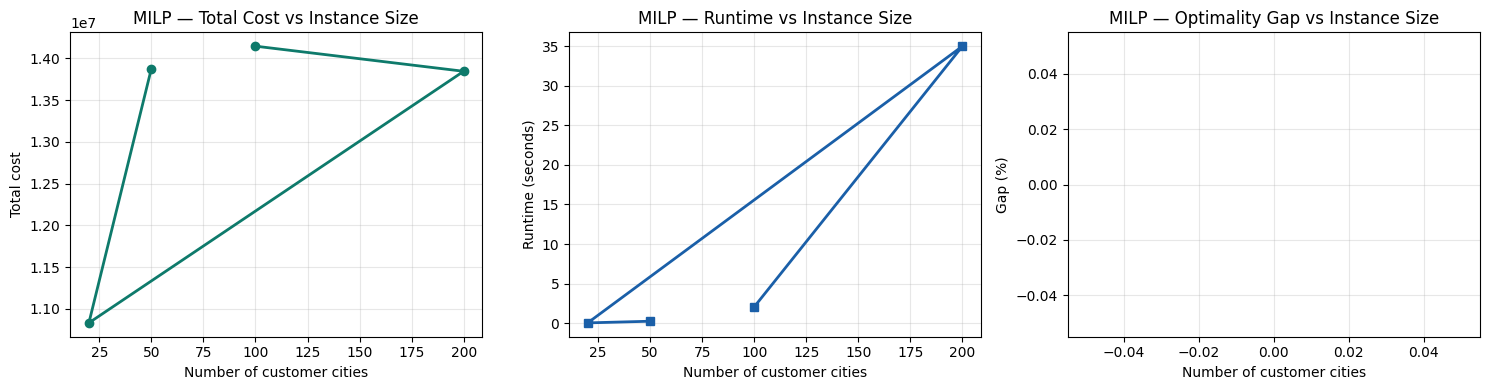

Plot saved to data/milp_plots.png


In [10]:
# ── Plot — Cost vs Instance Size ──────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sizes = df["Customers"].tolist()
costs = df["Cost (MILP)"].tolist()
runtimes = df["Runtime (s)"].tolist()
gaps = df["Gap (%)"].tolist()

# Cost
axes[0].plot(sizes, costs, marker="o", color="#0E7A6B", linewidth=2)
axes[0].set_title("MILP — Total Cost vs Instance Size")
axes[0].set_xlabel("Number of customer cities")
axes[0].set_ylabel("Total cost")
axes[0].grid(True, alpha=0.3)

# Runtime
axes[1].plot(sizes, runtimes, marker="s", color="#1A5FA8", linewidth=2)
axes[1].set_title("MILP — Runtime vs Instance Size")
axes[1].set_xlabel("Number of customer cities")
axes[1].set_ylabel("Runtime (seconds)")
axes[1].grid(True, alpha=0.3)

# Optimality gap
axes[2].plot(sizes, gaps, marker="^", color="#C0392B", linewidth=2)
axes[2].set_title("MILP — Optimality Gap vs Instance Size")
axes[2].set_xlabel("Number of customer cities")
axes[2].set_ylabel("Gap (%)")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plot_path = INSTANCE_DIR.parent / "milp_plots.png"
plt.savefig(plot_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Plot saved to {plot_path}")

In [11]:
# ── Detailed view of the largest instance ────────────────────────────
# Shows which cities were chosen as warehouses.

largest_path = INSTANCE_DIR / "cflp_n200_m40.json"
with open(largest_path) as f:
    inst = json.load(f)

res = solve_milp(inst, time_limit=TIME_LIMIT)

print(f"\nInstance: {inst['name']}")
print(f"Status  : {res['status']}")
print(f"Cost    : {res['objective']:,.2f}")
print(f"Gap     : {res['gap_pct']}%")
print(f"\nOpen warehouses ({len(res['open_warehouses'])})")
print("-" * 40)
for i in res["open_warehouses"]:
    fac = inst["facilities"][i]
    assigned = [j for j in range(inst["n_customers"]) if res["solution"][j] == i]
    load = sum(inst["customers"][j]["demand"] for j in assigned)
    print(f"  Warehouse {i:2d} | {fac['city']}, {fac['state']} "
          f"| load {load}/{fac['capacity']} "
          f"| serves {len(assigned)} cities")


Instance: cflp_n200_m40
Status  : Optimal
Cost    : 13,844,672.00
Gap     : None%

Open warehouses (10)
----------------------------------------
  Warehouse  4 | curitiba, PR | load 4493/20824 | serves 19 cities
  Warehouse  6 | porto alegre, RS | load 3128/20824 | serves 15 cities
  Warehouse  7 | salvador, BA | load 1807/20824 | serves 6 cities
  Warehouse 15 | goiania, GO | load 4157/20824 | serves 11 cities
  Warehouse 18 | recife, PE | load 2115/20824 | serves 7 cities
  Warehouse 20 | jundiai, SP | load 13966/20824 | serves 66 cities
  Warehouse 26 | contagem, MG | load 5886/20824 | serves 23 cities
  Warehouse 27 | sao goncalo, RJ | load 11812/20824 | serves 26 cities
  Warehouse 32 | sao luis, MA | load 1253/20824 | serves 5 cities
  Warehouse 35 | maua, SP | load 20794/20824 | serves 22 cities
